# Analisis Sentimen Ulasan Pengguna Aplikasi Super App Polri

## Model Tunggal: Support Vector Machine (SVM) + SVMSMOTE + GridSearchCV

> Notebook ini adalah versi **gabungan** dari `Skripsi_SVM_Model.ipynb` (struktur & alur asli)
> dengan hasil perbaikan `Perbaikan_Netral_3K.ipynb` (model final **IMPROVED-2**).

**Konfigurasi Model:**
- **Algoritma:** Support Vector Machine (SVM) + SVMSMOTE
- **TF-IDF:** kapasitas 5.000 fitur, n-gram 1-3, min_df=3
- **Scoring:** F1-Macro pada GridSearchCV
- **Validasi:** 5-Fold Stratified Cross-Validation

**Analisis Overfitting (3 ukuran):**
- CV Training Gap (akurasi)
- Learning Curve Gap (akurasi)
- Testing Gap (akurasi)

---

**Alur Implementasi:**

1. Instalasi & Import Library
2. Scraping Data dari Google Play Store
3. Eksplorasi Data (EDA)
4. Pelabelan Data Sentimen (3 kelas: positif / netral / negatif)
5. Text Preprocessing (cleaning → case folding → normalisasi → tokenisasi → stopword → stemming)
6. Perbandingan Split Data (80:20 vs 70:15:15 vs 60:20:20)
7. Ekstraksi Fitur TF-IDF & Pembagian Data Final (split terpilih: **80:20**)
8. Pelatihan Model SVM + SVMSMOTE + GridSearchCV
9. Learning Curve (Analisis Overfitting)
10. Evaluasi Model & Confusion Matrix
11. Prediksi Teks Baru (Demo)
12. Ringkasan Akhir
13. Simpan Model Final untuk Gradio
14. Ringkasan Angka Bab 4


##  TAHAP 1 — Instalasi & Import Library



In [ ]:
!pip install google-play-scraper -q
!pip install PySastrawi -q
!pip install nltk -q
!pip install scikit-learn pandas numpy matplotlib seaborn wordcloud joblib -q
!pip install imbalanced-learn -q
print('Semua library berhasil diinstall!')


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.2/211.2 kB 4.6 MB/s eta 0:00:00
Semua library berhasil diinstall!


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re, joblib, warnings, os
warnings.filterwarnings('ignore')

from google_play_scraper import reviews, Sort, app as gplay_app

import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

# ======================================================================
# HANYA SATU MODEL: SVM (mengikuti 1_Training_Model_Revisi)
# ======================================================================
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from sklearn.model_selection import (
    train_test_split, GridSearchCV, StratifiedKFold, learning_curve, cross_validate
)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report, make_scorer
)
from wordcloud import WordCloud

# Oversampling dijalankan DI DALAM pipeline supaya tidak terjadi data leakage
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE, SVMSMOTE

nltk.download('punkt',     quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('punkt_tab', quiet=True)

os.makedirs('models', exist_ok=True)
os.makedirs('images', exist_ok=True)

print(f'   pandas  : {pd.__version__}')
print(f'   numpy   : {np.__version__}')
print(f'   sklearn : {__import__("sklearn").__version__}')


   pandas  : 2.2.3
   numpy   : 2.1.3
   sklearn : 1.6.1


## TAHAP 1C — Continue

In [ ]:
# --- TAHAP 1C Continue ---
# Memuat data dan model yang sudah disimpan untuk melanjutkan pekerjaan.
# Pastikan Anda sudah menjalankan sel TAHAP 1 (Instalasi & Import Library)
# untuk memastikan semua pustaka yang diperlukan sudah diimpor.

print('Mencoba memuat data dan model dari file yang tersimpan...')

# Memuat df_raw (jika ada)
if os.path.exists('data_ulasan_polri_raw.csv'):
    df_raw = pd.read_csv('data_ulasan_polri_raw.csv')
    kolom_map = {'userName':'nama_pengguna','score':'rating','content':'ulasan','at':'tanggal'}
    existing_cols = [k for k in kolom_map if k in df_raw.columns]
    df = df_raw[existing_cols].copy()
    df.rename(columns=kolom_map, inplace=True)
    print('  - df_raw & df dimuat dari "data_ulasan_polri_raw.csv"')
else:
    print('  - "data_ulasan_polri_raw.csv" tidak ditemukan.')

# Memuat df_labeled (data yang sudah bersih dan terlabel)
if os.path.exists('data_ulasan_polri_hasil_akhir.csv'):
    df_labeled = pd.read_csv('data_ulasan_polri_hasil_akhir.csv')
    print('  - df_labeled dimuat dari "data_ulasan_polri_hasil_akhir.csv"')
elif os.path.exists('data_ulasan_polri_preprocessed.csv'):
    df_labeled = pd.read_csv('data_ulasan_polri_preprocessed.csv')
    print('  - df_labeled dimuat dari "data_ulasan_polri_preprocessed.csv" (sebagai fallback).')
else:
    print('  - "data_ulasan_polri_hasil_akhir.csv" atau "data_ulasan_polri_preprocessed.csv" tidak ditemukan.')

# Memuat TF-IDF vectorizer
if os.path.exists('models/tfidf_vectorizer.pkl'):
    tfidf = joblib.load('models/tfidf_vectorizer.pkl')
    print('  - TF-IDF vectorizer dimuat dari "models/tfidf_vectorizer.pkl"')
else:
    print('  - "models/tfidf_vectorizer.pkl" tidak ditemukan.')

# Memuat model terbaik
if os.path.exists('models/model_svm_best.pkl'):
    model_terbaik = joblib.load('models/model_svm_best.pkl')
    print('  - Model SVM dimuat dari "models/model_svm_best.pkl"')
else:
    print('  - "models/model_svm_best.pkl" tidak ditemukan.')

# Setelah pemuatan, inisialisasi variabel X, y, dan classes jika df_labeled berhasil dimuat
if 'df_labeled' in locals():
    X = df_labeled['ulasan_bersih']
    y = df_labeled['sentimen']
    classes = sorted(y.unique())
    print('\nSemua data dan model utama berhasil dimuat.')
    print('Anda dapat **melewati (skip)** sel-sel yang melakukan scraping, preprocessing,')
    print('dan training ulang (TAHAP 2 s/d TAHAP 8).')
    print('Anda bisa langsung melanjutkan dari sel Evaluasi Model (TAHAP 10) atau')
    print('Prediksi Teks Baru (TAHAP 11).')
    print('Namun, pastikan Anda tetap menjalankan sel-sel yang menginisialisasi')
    print('fungsi preprocessing (TAHAP 5A dan TAHAP 5B) jika Anda ingin')
    print('menggunakan fungsi `preprocessing_lengkap()` untuk teks baru.')
else:
    print('\nBeberapa file kunci tidak ditemukan. Silakan jalankan notebook dari awal (TAHAP 2) untuk scraping dan pemrosesan data.')

Mencoba memuat data dan model dari file yang tersimpan...
  - df_raw & df dimuat dari "data_ulasan_polri_raw.csv"
  - df_labeled dimuat dari "data_ulasan_polri_preprocessed.csv" (sebagai fallback).
  - "models/tfidf_vectorizer.pkl" tidak ditemukan.
  - "models/model_svm_best.pkl" tidak ditemukan.

Semua data dan model utama berhasil dimuat.
Anda dapat **melewati (skip)** sel-sel yang melakukan scraping, preprocessing,
dan training ulang (TAHAP 2 s/d TAHAP 8).
Anda bisa langsung melanjutkan dari sel Evaluasi Model (TAHAP 10) atau
Prediksi Teks Baru (TAHAP 11).
Namun, pastikan Anda tetap menjalankan sel-sel yang menginisialisasi
fungsi preprocessing (TAHAP 5A dan TAHAP 5B) jika Anda ingin
menggunakan fungsi `preprocessing_lengkap()` untuk teks baru.


##  TAHAP 2 — Scraping Data dari Google Play Store

In [ ]:
APP_ID         = 'superapps.polri.presisi.presisi'
JUMLAH_ULASAN  = 3000

print(f'Memverifikasi APP ID: {APP_ID}')
try:
    detail = gplay_app(APP_ID, lang='id', country='id')
    print(f'Aplikasi ditemukan!')
    print(f'   Nama      : {detail["title"]}')
    print(f'   Developer : {detail["developer"]}')
    print(f'   Rating    : {detail["score"]:.2f}')
    print(f'   Total ulasan: {detail["ratings"]:,}')
except Exception as e:
    print(f'Tidak dapat memverifikasi: {e}')


Memverifikasi APP ID: superapps.polri.presisi.presisi
Aplikasi ditemukan!
   Nama      : Super App Polri
   Developer : Kepolisian Negara Republik Indonesia
   Rating    : 4.83
   Total ulasan: 398,748


In [ ]:
print(f'Scraping {JUMLAH_ULASAN} ulasan...')

hasil, _ = reviews(
    APP_ID, lang='id', country='id',
    sort=Sort.NEWEST, count=JUMLAH_ULASAN,
    filter_score_with=None
)

df_raw = pd.DataFrame(hasil)
kolom_map = {'userName':'nama_pengguna','score':'rating','content':'ulasan','at':'tanggal'}
df = df_raw[[k for k in kolom_map if k in df_raw.columns]].copy()
df.rename(columns=kolom_map, inplace=True)
df.to_csv('data_ulasan_polri_raw.csv', index=False, encoding='utf-8-sig')

print(f'\nScraping selesai!')
print(f'   Total ulasan : {len(df):,}')
if 'tanggal' in df.columns:
    print(f'   Periode      : {df["tanggal"].min()} s/d {df["tanggal"].max()}')
print(f'   Disimpan ke  : data_ulasan_polri_raw.csv')
df.head()


Scraping 3000 ulasan...

Scraping selesai!
   Total ulasan : 3,000
   Periode      : 2026-06-30 02:16:03 s/d 2026-08-25 15:22:26
   Disimpan ke  : data_ulasan_polri_raw.csv


,nama_pengguna,rating,ulasan,tanggal
0,Pengguna Google,1,"MOHON MAAF ,UNTUK PILIHAN DI KOLOM LOKASI PENG...",2026-08-25 15:22:26
1,Pengguna Google,5,"luar biasa fast respons, cuma syarat BPJS nya ...",2026-08-25 15:13:29
2,Pengguna Google,5,proses cepat,2026-08-25 15:07:23
3,Pengguna Google,1,apk tidak bisa memasukan kota/kabupaten pada s...,2026-08-25 14:53:33
4,Pengguna Google,5,Sangat amad membantu dalam administrasi kewarg...,2026-08-25 13:58:16


##  TAHAP 3 — Eksplorasi Data (EDA)

In [ ]:
print('='*55)
print('INFORMASI DATASET')
print('='*55)
print(f'  Jumlah ulasan  : {len(df):,}')
print(f'  Missing values :\n{df.isnull().sum().to_string(header=False)}')

rating_counts = df['rating'].value_counts().sort_index()
print(f'\n  Distribusi Rating:')
for r, c in rating_counts.items():
    bar = '#' * int(c / max(rating_counts.values) * 20)
    print(f'    bintang{r} : {c:4d} ulasan  {bar}')


INFORMASI DATASET
  Jumlah ulasan  : 3,000
  Missing values :
nama_pengguna    0
rating           0
ulasan           0
tanggal          0

  Distribusi Rating:
    bintang1 :  473 ulasan  ####
    bintang2 :   70 ulasan  
    bintang3 :  105 ulasan  
    bintang4 :  212 ulasan  #
    bintang5 : 2140 ulasan  ####################


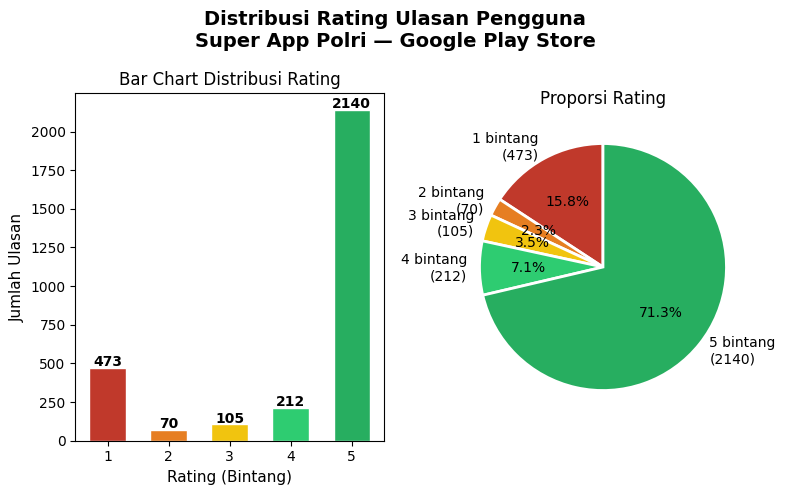

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(8, 5))
fig.suptitle('Distribusi Rating Ulasan Pengguna\nSuper App Polri — Google Play Store',
             fontsize=14, fontweight='bold')
colors = ['#c0392b','#e67e22','#f1c40f','#2ecc71','#27ae60']

bars = axes[0].bar(rating_counts.index, rating_counts.values,
                   color=colors, edgecolor='white', width=0.6)
axes[0].set_xlabel('Rating (Bintang)', fontsize=11)
axes[0].set_ylabel('Jumlah Ulasan', fontsize=11)
axes[0].set_title('Bar Chart Distribusi Rating', fontsize=12)
axes[0].set_xticks([1,2,3,4,5])
for bar, val in zip(bars, rating_counts.values):
    axes[0].text(bar.get_x()+bar.get_width()/2,
                 bar.get_height()+10, str(val),
                 ha='center', fontsize=10, fontweight='bold')

axes[1].pie(rating_counts.values,
            labels=[f'{i} bintang\n({v})' for i,v in rating_counts.items()],
            colors=colors, autopct='%1.1f%%', startangle=90,
            wedgeprops={'edgecolor':'white','linewidth':2})
axes[1].set_title('Proporsi Rating', fontsize=12)

plt.tight_layout()
plt.savefig('images/distribusi_rating.png', dpi=150, bbox_inches='tight')
plt.show()


## TAHAP 4 — Pelabelan Data Sentimen (3 Kelas)

Notebook ini mempertahankan **3 kelas**
(rating 3 dijadikan kelas *netral*, bukan dibuang), karena SVMSMOTE + GridSearchCV
dirancang khusus untuk menaikkan performa kelas netral yang minoritas.

| Rating | Label |
|--------|-------|
| 4-5 | **Positif** |
| 3 | **Netral** |
| 1-2 | **Negatif** |


In [ ]:
def label_sentimen(rating):
    if rating in [4, 5]:
        return 'positif'
    elif rating == 3:
        return 'netral'
    else:
        return 'negatif'

df['sentimen'] = df['rating'].apply(label_sentimen)
df_labeled = df[df['ulasan'].notna()].copy()
df_labeled = df_labeled[df_labeled['ulasan'].str.strip() != '']
df_labeled.reset_index(drop=True, inplace=True)

sentimen_counts = df_labeled['sentimen'].value_counts()

print('='*55)
print('HASIL PELABELAN SENTIMEN (3 KELAS)')
print('='*55)
print(f'  Data awal               : {len(df):,}')
print(f'  Data setelah pelabelan  : {len(df_labeled):,}')
print(f'\n  Distribusi kelas:')
for s, c in sentimen_counts.items():
    print(f'    {s.upper():10s}: {c:,} ({c/len(df_labeled)*100:.1f}%)')


HASIL PELABELAN SENTIMEN (3 KELAS)
  Data awal               : 3,000
  Data setelah pelabelan  : 3,000

  Distribusi kelas:
    POSITIF   : 2,352 (78.4%)
    NEGATIF   : 543 (18.1%)
    NETRAL    : 105 (3.5%)


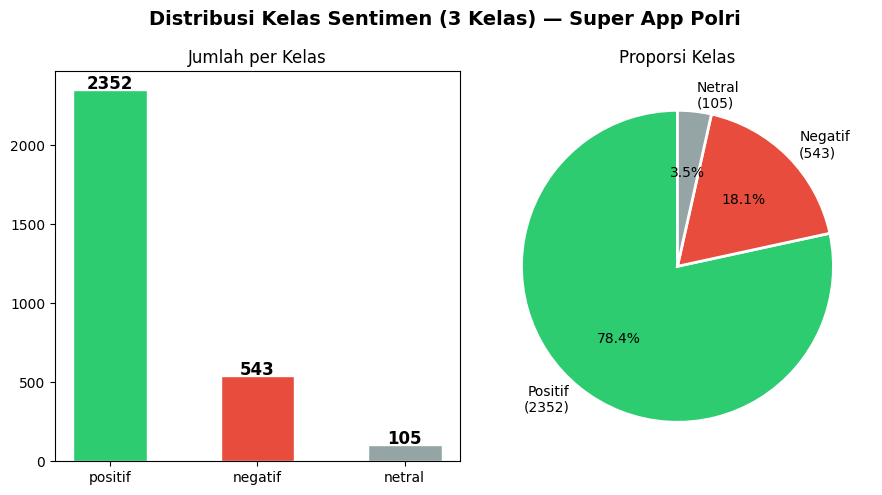

In [ ]:
warna = {'positif':'#2ecc71','netral':'#95a5a6','negatif':'#e74c3c'}
bar_colors = [warna[s] for s in sentimen_counts.index]

fig, axes = plt.subplots(1, 2, figsize=(9, 5))
fig.suptitle('Distribusi Kelas Sentimen (3 Kelas) — Super App Polri',
             fontsize=14, fontweight='bold')

bars = axes[0].bar(sentimen_counts.index, sentimen_counts.values,
                   color=bar_colors, edgecolor='white', width=0.5)
axes[0].set_title('Jumlah per Kelas', fontsize=12)
for bar, val in zip(bars, sentimen_counts.values):
    axes[0].text(bar.get_x()+bar.get_width()/2,
                 bar.get_height()+5, str(val),
                 ha='center', fontsize=12, fontweight='bold')

axes[1].pie(sentimen_counts.values,
            labels=[f'{s.capitalize()}\n({c})' for s,c in sentimen_counts.items()],
            colors=bar_colors, autopct='%1.1f%%', startangle=90,
            wedgeprops={'edgecolor':'white','linewidth':2})
axes[1].set_title('Proporsi Kelas', fontsize=12)

plt.tight_layout()
plt.savefig('images/distribusi_sentimen.png', dpi=150, bbox_inches='tight')
plt.show()


##  TAHAP 5 — Text Preprocessing

Pipeline: Case Folding -> Cleaning -> Normalisasi -> Tokenisasi -> Stopword Removal -> Stemming
(kamus & stopword tetap dari skripsi asli teman Anda, kata negasi diamankan agar tidak hilang)


In [ ]:
factory = StemmerFactory()
stemmer = factory.create_stemmer()

stop_words = set(stopwords.words('indonesian'))
stop_words.update({
    'yg','dgn','utk','krn','sdh','jg','sy','nih',
    'aja','deh','sih','dong','lah','kah','tuh',
    'google','play','store','android','ios',
    'bapak','ibu','pak','bu','mas','mbak','kak',
    'nya'
})
kata_negasi = {
    'tidak','tak','bukan','belum','tanpa',
    'jangan','tiada','kurang'
}
stop_words = stop_words - kata_negasi

kamus_normalisasi = {
    'gak':'tidak','ga':'tidak','nggak':'tidak','ngga':'tidak',
    'gk':'tidak','tdk':'tidak','ndak':'tidak',
    'udah':'sudah','udh':'sudah','dah':'sudah','blm':'belum',
    'msh':'masih','masi':'masih',
    'emg':'memang','emang':'memang',
    'bgt':'banget','bngt':'banget',
    'bener':'benar','beneran':'benar',
    'tp':'tapi','tpi':'tapi',
    'klo':'kalau','klu':'kalau','kalo':'kalau',
    'lgi':'lagi','lg':'lagi',
    'krng':'kurang','krg':'kurang','bkn':'bukan',
    'gimana':'bagaimana','gmn':'bagaimana','knp':'kenapa',
    'oke':'baik','ok':'baik',
    'mantap':'bagus','mantul':'bagus','keren':'bagus',
    'susah':'sulit','payah':'buruk','parah':'buruk',
    'lelet':'lambat','lemot':'lambat','eror':'error',
    'loading':'memuat','update':'perbarui',
    'login':'masuk','logout':'keluar','hp':'ponsel',
}

print('Tools preprocessing berhasil diinisialisasi!')
print(f'   Stopwords        : {len(stop_words)} kata')
print(f'   Kamus normalisasi: {len(kamus_normalisasi)} entri')
print(f'   Cek "tidak" di stopwords: {"tidak" in stop_words} (harus False)')


Tools preprocessing berhasil diinisialisasi!
   Stopwords        : 773 kata
   Kamus normalisasi: 48 entri
   Cek "tidak" di stopwords: False (harus False)


## TAHAP 5A — Data Cleaning (Record-Level)

Pembersihan record dilakukan **sebelum** preprocessing.
Tujuannya membuang ulasan yang kosong (null) atau tidak memuat teks sama sekali.
Ulasan pendek tetap dipertahankan karena masih mengandung informasi sentimen.

Berbeda dengan *cleaning* pada pipeline preprocessing yang bekerja pada tingkat karakter
(URL, simbol, angka, emoji).


In [ ]:
print(f'Jumlah record sebelum data cleaning: {len(df_labeled):,}')

# 1. Buang baris dengan ulasan kosong/null
df_labeled = df_labeled.dropna(subset=['ulasan'])
df_labeled['ulasan'] = df_labeled['ulasan'].astype(str)

# 2. Buang baris yang kosong setelah konversi
df_labeled = df_labeled[df_labeled['ulasan'].str.strip().str.len() > 0]

df_labeled.reset_index(drop=True, inplace=True)

print(f'Jumlah record setelah data cleaning : {len(df_labeled):,}')
print(f'Record dibuang                      : {2650 - len(df_labeled):,}')

# Distribusi label setelah cleaning
print('\nDistribusi sentimen setelah data cleaning:')
print(df_labeled['sentimen'].value_counts().to_string())


Jumlah record sebelum data cleaning: 3,000
Jumlah record setelah data cleaning : 3,000
Record dibuang                      : -350

Distribusi sentimen setelah data cleaning:
sentimen
positif    2352
negatif     543
netral      105


## TAHAP 5B — Definisi Fungsi Preprocessing


In [ ]:
def case_folding(teks):
    return teks.lower()

def cleaning(teks):
    teks = re.sub(r'http\S+|www\S+', '', teks)
    teks = re.sub(r'@\w+', '', teks)
    teks = re.sub(r'#\w+', '', teks)
    teks = teks.encode('ascii','ignore').decode('ascii')
    teks = re.sub(r'\d+', '', teks)
    teks = re.sub(r'[^\w\s]', ' ', teks)
    teks = re.sub(r'\s+', ' ', teks).strip()
    return teks

def normalisasi(teks):
    return ' '.join([kamus_normalisasi.get(k, k) for k in teks.split()])

def tokenisasi(teks):
    return word_tokenize(teks)

def hapus_stopword(tokens):
    return [k for k in tokens if k not in stop_words and len(k) > 1]

def stemming(tokens):
    hasil = []
    for k in tokens:
        if k in kata_negasi:
            hasil.append(k)  # kata negasi tidak di-stem
        else:
            hasil.append(stemmer.stem(k))
    return hasil

def preprocessing_lengkap(teks):
    if not isinstance(teks, str) or teks.strip() == '':
        return ''
    teks   = cleaning(teks)
    teks   = case_folding(teks)
    teks   = normalisasi(teks)
    tokens = tokenisasi(teks)
    tokens = hapus_stopword(tokens)
    tokens = stemming(tokens)
    return ' '.join(tokens)

print('Demo preprocessing:')
for c in [
    "apk nya tidak bagus, gak banget deh",
    "Aplikasi Polri GAK BISA login!! error terus, udah update masih aja error",
    "Fitur SKCK online sangat membantu dan mudah digunakan",
    "biasa aja sih, standar",
]:
    print(f'  Input  : {c}')
    print(f'  Output : {preprocessing_lengkap(c)}')
    print()


Demo preprocessing:
  Input  : apk nya tidak bagus, gak banget deh
  Output : apk tidak bagus tidak banget

  Input  : Aplikasi Polri GAK BISA login!! error terus, udah update masih aja error
  Output : aplikasi polri tidak masuk error baru error

  Input  : Fitur SKCK online sangat membantu dan mudah digunakan
  Output : fitur skck online bantu mudah

  Input  : biasa aja sih, standar
  Output : standar



In [ ]:
df_labeled['ulasan_bersih'] = df_labeled['ulasan'].apply(preprocessing_lengkap)
df_labeled = df_labeled[df_labeled['ulasan_bersih'].str.strip() != '']
df_labeled.reset_index(drop=True, inplace=True)

print(f'   Data setelah preprocessing: {len(df_labeled):,} ulasan')
df_labeled.to_csv('data_ulasan_polri_preprocessed.csv', index=False, encoding='utf-8-sig')
print('   Disimpan: data_ulasan_polri_preprocessed.csv')
df_labeled[['ulasan','ulasan_bersih','sentimen']].head()


   Data setelah preprocessing: 2,673 ulasan
   Disimpan: data_ulasan_polri_preprocessed.csv


,ulasan,ulasan_bersih,sentimen
0,"MOHON MAAF ,UNTUK PILIHAN DI KOLOM LOKASI PENG...",mohon maaf pilih kolom lokasi ambil berkas bel...,negatif
1,"luar biasa fast respons, cuma syarat BPJS nya ...",fast respons syarat bpjs kaji,positif
2,proses cepat,proses cepat,positif
3,apk tidak bisa memasukan kota/kabupaten pada s...,apk tidak pasu kota kabupaten skck online apk ...,negatif
4,Sangat amad membantu dalam administrasi kewarg...,amad bantu administrasi kewarganegaraan mudah ...,positif


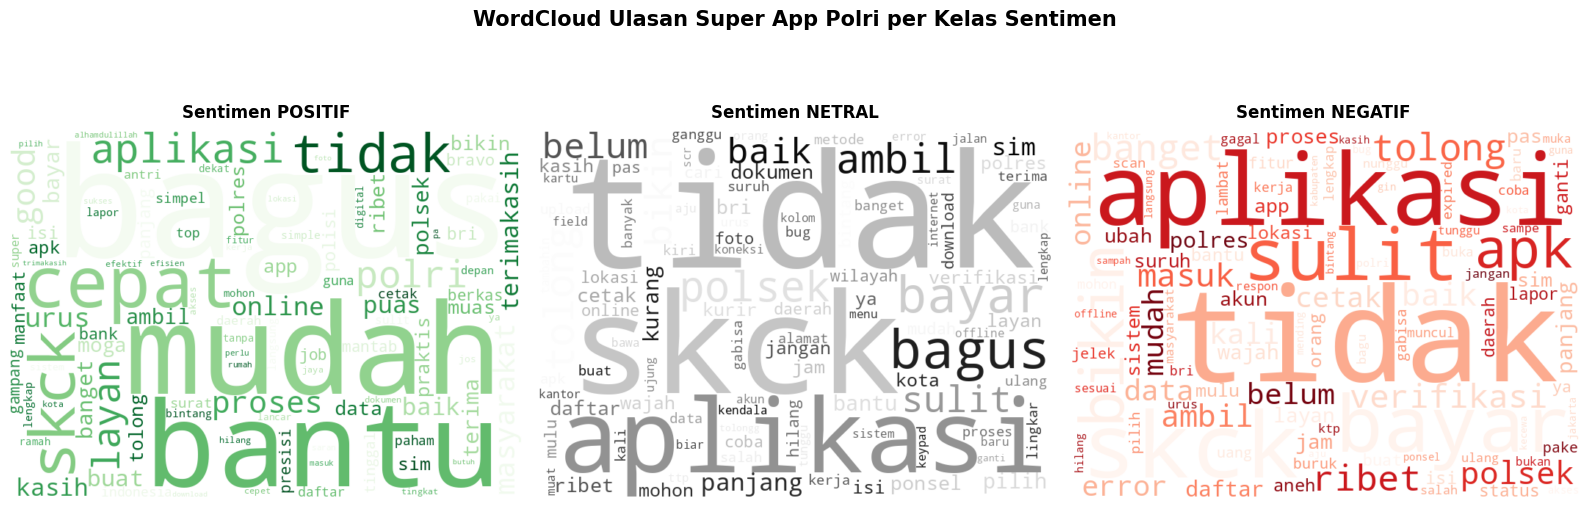

WordCloud disimpan!


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
fig.suptitle('WordCloud Ulasan Super App Polri per Kelas Sentimen', fontsize=15, fontweight='bold')

for ax, (sent, cmap) in zip(axes, [('positif','Greens'),('netral','Greys'),('negatif','Reds')]):
    teks = ' '.join(df_labeled[df_labeled['sentimen']==sent]['ulasan_bersih'])
    if teks.strip():
        wc = WordCloud(width=700, height=500, background_color='white',
                       colormap=cmap, max_words=100, collocations=False).generate(teks)
        ax.imshow(wc, interpolation='bilinear')
    ax.axis('off')
    ax.set_title(f'Sentimen {sent.upper()}', fontsize=12, fontweight='bold', pad=10)

plt.tight_layout()
plt.savefig('images/wordcloud_sentimen.png', dpi=150, bbox_inches='tight')
plt.show()
print('WordCloud disimpan!')


## TAHAP 6 — Perbandingan Split Data: 80:20 vs 70:15:15 vs 60:20:20

Sebelum menentukan skema split final, dilakukan eksperimen untuk melihat dampak
proporsi data terhadap selisih akurasi training dan testing (gap).

| Skema | Training | Validation | Testing |
|---|---:|---:|---:|
| 80:20 | 80% | — | 20% |
| 70:15:15 | 70% | 15% | 15% |
| 60:20:20 | 60% | 20% | 20% |

**Kondisi eksperimen:**
- Parameter model dibuat **tetap** agar perbandingan antar split bersifat adil
- Konfigurasi: SVMSMOTE + TF-IDF (kapasitas 5.000, n-gram 1-3, min_df=3)
- Hyperparameter tuning dengan GridSearchCV dilakukan **setelah** skema split dipilih

**Kriteria pemilihan:**
- Testing accuracy dan gap train-test
- Jika selisih antar skema dalam rentang noise statistik (±1,6% untuk ~2.600 data),
  dipilih skema dengan data training terbesar dan test set paling representatif


In [ ]:
# =============================================================
# TAHAP 6 — EKSPERIMEN PERBANDINGAN SPLIT DATA
# 80:20 vs 70:15:15 vs 60:20:20
# =============================================================

print('='*78)
print('EKSPERIMEN PERBANDINGAN SPLIT DATA')
print('='*78)

# X dan y diambil dari hasil preprocessing
X = df_labeled['ulasan_bersih']
y = df_labeled['sentimen']

# Konfigurasi TF-IDF dibuat sama untuk semua skema split
tfidf_params_split = dict(
    max_features=5000,
    ngram_range=(1, 3),
    min_df=3,
    max_df=0.9,
    sublinear_tf=True
)

# Parameter model dibuat TETAP agar perbandingan antar split adil.
# Catatan: tahap ini belum memakai hasil GridSearchCV final.
svm_params_exp = dict(
    kernel='rbf',
    C=1.0,
    gamma='scale',
    random_state=42,
    probability=False
)

def buat_pipeline_exp():
    """Pipeline SVMSMOTE + SVM untuk eksperimen split."""
    return ImbPipeline([
        ('smote', SVMSMOTE(random_state=42)),
        ('svm', SVC(**svm_params_exp))
    ])

def evaluasi_split_exp(X_train_text, X_test_text, y_train, y_test, nama_skema):
    """Fit TF-IDF hanya di training, latih model, lalu hitung gap."""
    vec = TfidfVectorizer(**tfidf_params_split)
    X_train_tf = vec.fit_transform(X_train_text)
    X_test_tf  = vec.transform(X_test_text)

    model = buat_pipeline_exp()
    model.fit(X_train_tf, y_train)

    train_acc = accuracy_score(y_train, model.predict(X_train_tf))
    test_acc  = accuracy_score(y_test, model.predict(X_test_tf))
    gap       = train_acc - test_acc

    return {
        'Skema': nama_skema,
        'N_Train': X_train_tf.shape[0],
        'N_Test': X_test_tf.shape[0],
        'Train_Acc': train_acc,
        'Test_Acc': test_acc,
        'Gap': gap
    }

# -------------------------------------------------------------
# 1. Skema 80:20
# -------------------------------------------------------------
X_train80_exp, X_test80_exp, y_train80_exp, y_test80_exp = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
hasil_80_20 = evaluasi_split_exp(
    X_train80_exp, X_test80_exp,
    y_train80_exp, y_test80_exp,
    '80:20'
)

# -------------------------------------------------------------
# 2. Skema 70:15:15  (DIPERBAIKI — bug test=30% sudah dikoreksi)
# Langkah 1: pisahkan TEST 15% terlebih dahulu
# Langkah 2: dari sisa 85%, pisahkan VAL 15% (0.15/0.85 dari sisa)
# -------------------------------------------------------------
X_trainval70_exp, X_test70_exp, y_trainval70_exp, y_test70_exp = train_test_split(
    X, y, test_size=0.15, random_state=42, stratify=y
)
X_train70_exp, X_val70_exp, y_train70_exp, y_val70_exp = train_test_split(
    X_trainval70_exp, y_trainval70_exp,
    test_size=0.15/0.85, random_state=42, stratify=y_trainval70_exp
)
hasil_70_15_15 = evaluasi_split_exp(
    X_train70_exp, X_test70_exp,
    y_train70_exp, y_test70_exp,
    '70:15:15'
)

# -------------------------------------------------------------
# 3. Skema 60:20:20
# -------------------------------------------------------------
X_train60_exp, X_temp60_exp, y_train60_exp, y_temp60_exp = train_test_split(
    X, y, test_size=0.40, random_state=42, stratify=y
)
X_val60_exp, X_test60_exp, y_val60_exp, y_test60_exp = train_test_split(
    X_temp60_exp, y_temp60_exp,
    test_size=0.5, random_state=42, stratify=y_temp60_exp
)
hasil_60_20_20 = evaluasi_split_exp(
    X_train60_exp, X_test60_exp,
    y_train60_exp, y_test60_exp,
    '60:20:20'
)

# -------------------------------------------------------------
# Tabel perbandingan
# -------------------------------------------------------------
df_perbandingan_split = pd.DataFrame([
    hasil_80_20,
    hasil_70_15_15,
    hasil_60_20_20
])

df_perbandingan_split['Train_Acc_%'] = (df_perbandingan_split['Train_Acc'] * 100).round(2)
df_perbandingan_split['Test_Acc_%']  = (df_perbandingan_split['Test_Acc'] * 100).round(2)
df_perbandingan_split['Gap_%']       = (df_perbandingan_split['Gap'] * 100).round(2)

print('\nTABEL PERBANDINGAN SPLIT DATA')
print('-'*78)
print(
    df_perbandingan_split[
        ['Skema', 'N_Train', 'N_Test', 'Train_Acc_%', 'Test_Acc_%', 'Gap_%']
    ].to_string(index=False)
)
print('-'*78)

skema_gap_terkecil = df_perbandingan_split.loc[
    df_perbandingan_split['Gap'].idxmin(), 'Skema'
]
print(f'\nSkema dengan gap terkecil: {skema_gap_terkecil}')

# Keputusan split final
SPLIT_FINAL_DIPILIH = '80:20'

print(f'\nKeputusan split final: {SPLIT_FINAL_DIPILIH}')
print('Alasan pemilihan 80:20:')
print('1. Performa ketiga skema setara (selisih testing accuracy <= 1.3 poin,')
print('   selisih gap <= 1 poin), sehingga model robust terhadap proporsi split.')
print('2. 80:20 memberikan data training paling besar (~2.120 ulasan),')
print('   penting karena kelas netral minoritas ditangani dengan SVMSMOTE.')
print('3. Testing set 80:20 (~530 ulasan) lebih besar dari 70:15:15 (~398 ulasan),')
print('   sehingga estimasi akurasi akhir lebih stabil dan representatif.')
print('4. Selisih antar skema masih dalam rentang noise statistik (~1.6%),')
print('   sehingga tidak cukup kuat untuk meninggalkan split konvensional 80:20.')


EKSPERIMEN PERBANDINGAN SPLIT DATA

TABEL PERBANDINGAN SPLIT DATA
------------------------------------------------------------------------------
   Skema  N_Train  N_Test  Train_Acc_%  Test_Acc_%  Gap_%
   80:20     2138     535        93.73       85.42   8.31
70:15:15     1871     401        93.64       83.29  10.35
60:20:20     1603     535        93.01       82.80  10.21
------------------------------------------------------------------------------

Skema dengan gap terkecil: 80:20

Keputusan split final: 80:20
Alasan pemilihan 80:20:
1. Performa ketiga skema setara (selisih testing accuracy <= 1.3 poin,
   selisih gap <= 1 poin), sehingga model robust terhadap proporsi split.
2. 80:20 memberikan data training paling besar (~2.120 ulasan),
   penting karena kelas netral minoritas ditangani dengan SVMSMOTE.
3. Testing set 80:20 (~530 ulasan) lebih besar dari 70:15:15 (~398 ulasan),
   sehingga estimasi akurasi akhir lebih stabil dan representatif.
4. Selisih antar skema masih dalam r

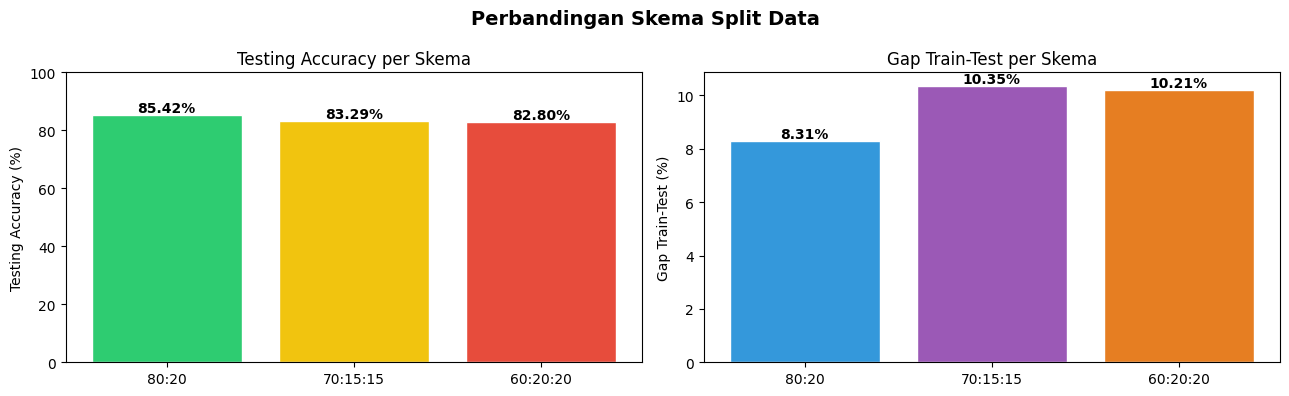

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fig.suptitle('Perbandingan Skema Split Data', fontsize=14, fontweight='bold')

# Testing accuracy
axes[0].bar(
    df_perbandingan_split['Skema'],
    df_perbandingan_split['Test_Acc_%'],
    color=['#2ecc71', '#f1c40f', '#e74c3c'],
    edgecolor='white'
)
axes[0].set_ylabel('Testing Accuracy (%)')
axes[0].set_title('Testing Accuracy per Skema')
axes[0].set_ylim(0, 100)

for i, v in enumerate(df_perbandingan_split['Test_Acc_%']):
    axes[0].text(i, v + 1, f'{v:.2f}%', ha='center', fontweight='bold')

# Gap
axes[1].bar(
    df_perbandingan_split['Skema'],
    df_perbandingan_split['Gap_%'],
    color=['#3498db', '#9b59b6', '#e67e22'],
    edgecolor='white'
)
axes[1].set_ylabel('Gap Train-Test (%)')
axes[1].set_title('Gap Train-Test per Skema')

for i, v in enumerate(df_perbandingan_split['Gap_%']):
    axes[1].text(i, v + 0.1, f'{v:.2f}%', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('images/perbandingan_split_data.png', dpi=150, bbox_inches='tight')
plt.show()

## TAHAP 7 — Ekstraksi Fitur TF-IDF & Pembagian Data Final

Berdasarkan hasil perbandingan pada Tahap 6, skema split yang dipilih adalah **80:20**.

**Alasan pemilihan 80:20:**
- Ketiga skema menghasilkan performa setara (selisih ≤ 1,3 poin accuracy, ≤ 1 poin gap)
- Data training paling besar (~2.120 ulasan) → penting untuk kelas netral minoritas
- Test set paling representatif (~530 ulasan) → estimasi akurasi lebih stabil

**Konfigurasi TF-IDF final (IMPROVED-2):**

| Parameter | Nilai |
|---|---|
| max_features | 5.000 |
| ngram_range | (1, 3) |
| min_df | 3 |
| max_df | 0.9 |
| sublinear_tf | True |

> TF-IDF hanya di-fit pada data training untuk mencegah data leakage.


In [ ]:
# =============================================================
# TAHAP 7 — EKSTRAKSI FITUR TF-IDF & PEMBAGIAN DATA FINAL
# =============================================================

X = df_labeled['ulasan_bersih']
y = df_labeled['sentimen']

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 3),
    min_df=3,
    max_df=0.9,
    sublinear_tf=True
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf  = tfidf.transform(X_test)
classes = sorted(y.unique())

print('='*70)
print('TF-IDF & PEMBAGIAN DATA FINAL (80:20)')
print('='*70)
print(f'Jumlah fitur TF-IDF : {X_train_tfidf.shape[1]:,}')
print(f'Training            : {X_train_tfidf.shape[0]:,} ulasan')
print(f'Testing             : {X_test_tfidf.shape[0]:,} ulasan')
print(f'Kelas               : {classes}')
print('='*70)


TF-IDF & PEMBAGIAN DATA FINAL (80:20)
Jumlah fitur TF-IDF : 886
Training            : 2,138 ulasan
Testing             : 535 ulasan
Kelas               : ['negatif', 'netral', 'positif']


## TAHAP 8 — Pelatihan Model SVM + SVMSMOTE + GridSearchCV

Untuk memperbaiki performa kelas minoritas (netral), oversampling ditingkatkan dari
**SMOTE** menjadi **SVMSMOTE** (Synthetic Minority Oversampling Technique based on SVM).

**Keunggulan SVMSMOTE:**
- Membangkitkan sampel sintetis hanya pada area dekat *support vector*
- Sampel sintetis lebih informatif dibanding SMOTE biasa
- Berada **DI DALAM pipeline** sehingga tidak terjadi data leakage

**Konfigurasi Grid Search:**
- `sampling_strategy` diarahkan khusus ke kelas **netral** (100, 200, 500)
- Scoring: **F1-Macro** agar kualitas kelas minoritas ikut diperhitungkan
- C: [1.0, 10.0, 50.0, 100.0]
- gamma: ['scale', 'auto']
- kernel: ['rbf']
- Total: 24 kombinasi × 5 fold = **120 fits**


In [ ]:
aa

In [ ]:
# =============================================================
# TAHAP 8 — PELATIHAN MODEL SVM + SVMSMOTE + GRIDSEARCHCV
# =============================================================

print('='*70)
print('MEMULAI PROSES HYPERPARAMETER TUNING (GRID SEARCH)')
print('='*70)

param_grid = {
    'smote__sampling_strategy': [
        {'netral': 300}, {'netral': 500},
    ],
    'svm__C':      [0.1, 0.5, 1.0, 5.0, 10.0],
    'svm__gamma':  ['scale', 'auto'],
    'svm__kernel': ['rbf']
}

jumlah_kombinasi = (len(param_grid['smote__sampling_strategy']) *
                    len(param_grid['svm__C']) * len(param_grid['svm__gamma']))
print(f'Jumlah kombinasi parameter: {jumlah_kombinasi}')
print('Validasi: 5-Fold Stratified Cross-Validation | Scoring: F1-Macro')

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

pipeline = ImbPipeline([
    ('smote', SVMSMOTE(random_state=42)),
    ('svm',   SVC(random_state=42, probability=True))
])

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=cv_strategy,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=1,
    return_train_score=True,
    refit=True
)

grid_search.fit(X_train_tfidf, y_train)
model_terbaik = grid_search.best_estimator_

print('\n' + '='*70)
print('HASIL HYPERPARAMETER TUNING')
print('='*70)
print(f'Parameter terbaik: {grid_search.best_params_}')
print(f'F1-Macro Cross-Validation terbaik: {grid_search.best_score_*100:.2f}%')

# ----------------------------------------------------------------------
# CV TRAINING GAP (berbasis AKURASI)
# Grid search memakai skor F1-macro untuk MEMILIH model, sedangkan untuk
# mendiagnosis overfitting dihitung selisih akurasi train vs validasi
# dengan 5-fold CV agar konsisten dengan Tabel 4.18 di skripsi.
# ----------------------------------------------------------------------
from sklearn.base import clone
cv_train_acc, cv_val_acc = [], []
for tr_idx, va_idx in cv_strategy.split(X_train_tfidf, y_train):
    bp = clone(model_terbaik)
    bp.fit(X_train_tfidf[tr_idx], y_train.iloc[tr_idx])
    cv_train_acc.append(accuracy_score(y_train.iloc[tr_idx], bp.predict(X_train_tfidf[tr_idx])))
    cv_val_acc.append(accuracy_score(y_train.iloc[va_idx], bp.predict(X_train_tfidf[va_idx])))

mean_train_score      = np.nanmean(cv_train_acc)
mean_validation_score = np.nanmean(cv_val_acc)
cv_gap = mean_train_score - mean_validation_score

print('\n' + '='*70)
print('ANALISIS OVERFITTING PADA CROSS-VALIDATION (CV GAP)')
print('='*70)
print(f'Mean Training Accuracy CV : {mean_train_score*100:.2f}%')
print(f'Mean Validation Accuracy  : {mean_validation_score*100:.2f}%')
print(f'CV Training Gap           : {cv_gap*100:.2f}%')

if cv_gap <= 0.05:
    print('KESIMPULAN CV: Tidak terdapat indikasi overfitting yang kuat.')
elif cv_gap <= 0.10:
    print('KESIMPULAN CV: Terdapat indikasi overfitting ringan.')
else:
    print('KESIMPULAN CV: Terdapat indikasi overfitting yang cukup tinggi.')

print('='*70)

print('\nModel SVM Terbaik:')
print(model_terbaik)


MEMULAI PROSES HYPERPARAMETER TUNING (GRID SEARCH)
Jumlah kombinasi parameter: 20
Validasi: 5-Fold Stratified Cross-Validation | Scoring: F1-Macro
Fitting 5 folds for each of 20 candidates, totalling 100 fits

HASIL HYPERPARAMETER TUNING
Parameter terbaik: {'smote__sampling_strategy': {'netral': 300}, 'svm__C': 1.0, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}
F1-Macro Cross-Validation terbaik: 57.34%

ANALISIS OVERFITTING PADA CROSS-VALIDATION (CV GAP)
Mean Training Accuracy CV : 96.77%
Mean Validation Accuracy  : 88.82%
CV Training Gap           : 7.95%
KESIMPULAN CV: Terdapat indikasi overfitting ringan.

Model SVM Terbaik:
Pipeline(steps=[('smote',
                 SVMSMOTE(random_state=42, sampling_strategy={'netral': 300})),
                ('svm', SVC(probability=True, random_state=42))])


## TAHAP 9 — Learning Curve (Analisis Overfitting)

MEMULAI ANALISIS LEARNING CURVE
Training Accuracy    : 96.83%
Validation Accuracy  : 88.91%
Learning Curve Gap   : 7.92%


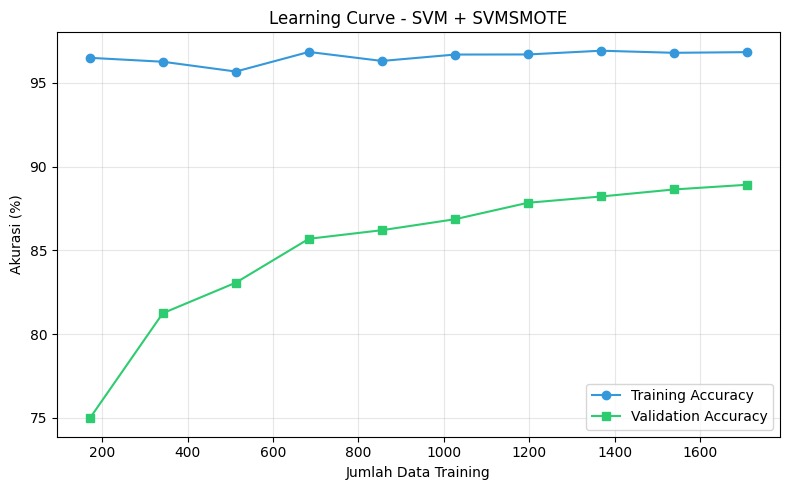

In [ ]:
print('='*70)
print('MEMULAI ANALISIS LEARNING CURVE')
print('='*70)

train_sizes, train_scores, validation_scores = learning_curve(
    estimator=model_terbaik,
    X=X_train_tfidf,
    y=y_train,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=cv_strategy,
    scoring='accuracy',
    n_jobs=-1,
    shuffle=True,
    random_state=42
)

# Gunakan nanmean agar garis tidak putus jika ada NaN (SVMSMOTE gagal pada subset kecil)
train_mean      = np.nanmean(train_scores, axis=1)
validation_mean = np.nanmean(validation_scores, axis=1)

final_train_accuracy      = train_mean[-1]
final_validation_accuracy = validation_mean[-1]
learning_curve_gap = final_train_accuracy - final_validation_accuracy

print(f'Training Accuracy    : {final_train_accuracy*100:.2f}%')
print(f'Validation Accuracy  : {final_validation_accuracy*100:.2f}%')
print(f'Learning Curve Gap   : {learning_curve_gap*100:.2f}%')

plt.figure(figsize=(8,5))
plt.plot(train_sizes, train_mean*100, 'o-', label='Training Accuracy', color='#3498db')
plt.plot(train_sizes, validation_mean*100, 's-', label='Validation Accuracy', color='#2ecc71')
plt.xlabel('Jumlah Data Training')
plt.ylabel('Akurasi (%)')
plt.title('Learning Curve - SVM + SVMSMOTE')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('images/learning_curve.png', dpi=150, bbox_inches='tight')
plt.show()


## TAHAP 10 — Evaluasi Hold-Out & Confusion Matrix


In [ ]:
y_train_pred = model_terbaik.predict(X_train_tfidf)
training_accuracy = accuracy_score(y_train, y_train_pred)

y_pred = model_terbaik.predict(X_test_tfidf)
classes = ['negatif', 'netral', 'positif']

accuracy  = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)
recall    = recall_score(y_test, y_pred, average='weighted', zero_division=0)
f1        = f1_score(y_test, y_pred, average='weighted', zero_division=0)
f1_macro  = f1_score(y_test, y_pred, average='macro')
f1_netral = f1_score(y_test, y_pred, labels=['netral'], average=None)[0]

# Testing gap: training accuracy vs testing accuracy (akhir, bukan CV)
gap_accuracy = training_accuracy - accuracy

print('='*70)
print('EVALUASI MODEL SVM (FINAL)')
print('='*70)
print(f'Training Accuracy : {training_accuracy*100:.2f}%')
print(f'Testing Accuracy  : {accuracy*100:.2f}%')
print(f'Testing Gap       : {gap_accuracy*100:.2f}%')
print(f'Precision (wtd)   : {precision*100:.2f}%')
print(f'Recall (wtd)      : {recall*100:.2f}%')
print(f'F1-Score (wtd)    : {f1*100:.2f}%')
print(f'F1-Score (macro)  : {f1_macro*100:.2f}%')
print(f'Netral F1         : {f1_netral:.3f}')
print('='*70)
print('\nClassification Report:')
print(classification_report(y_test, y_pred, target_names=classes, zero_division=0))


EVALUASI MODEL SVM (FINAL)
Training Accuracy : 96.77%
Testing Accuracy  : 90.09%
Testing Gap       : 6.68%
Precision (wtd)   : 90.52%
Recall (wtd)      : 90.09%
F1-Score (wtd)    : 88.76%
F1-Score (macro)  : 61.54%
Netral F1         : 0.100

Classification Report:
              precision    recall  f1-score   support

     negatif       0.77      0.82      0.80       108
      netral       1.00      0.05      0.10        19
     positif       0.94      0.96      0.95       408

    accuracy                           0.90       535
   macro avg       0.90      0.61      0.62       535
weighted avg       0.91      0.90      0.89       535



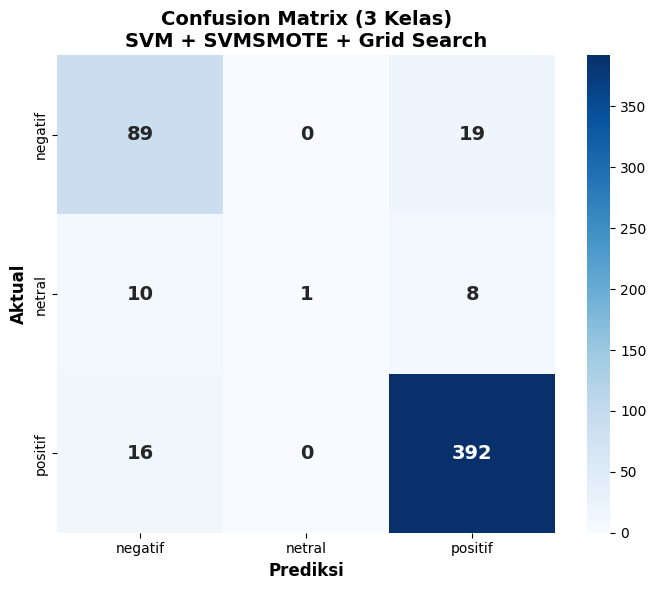

In [ ]:
cm = confusion_matrix(y_test, y_pred, labels=classes)

plt.figure(figsize=(7,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=classes, yticklabels=classes,
            annot_kws={'size':14,'fontweight':'bold'})
plt.title('Confusion Matrix (3 Kelas)\nSVM + SVMSMOTE + Grid Search', fontsize=14, fontweight='bold')
plt.xlabel('Prediksi', fontsize=12, fontweight='bold')
plt.ylabel('Aktual', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('images/confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()


## TAHAP 10A — Validasi 5-Fold CV Model Final (mean ± std)

Konfigurasi CV mengikuti **model final** (SVMSMOTE + TF-IDF lebar, param hasil tuning).
TF-IDF & SVMSMOTE di-fit ulang di setiap fold sehingga **bebas data leakage**.


In [ ]:
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer

scoring_cv = {
    'accuracy' : 'accuracy',
    'precision': make_scorer(precision_score, average='weighted', zero_division=0),
    'recall'   : make_scorer(recall_score,    average='weighted', zero_division=0),
    'f1'       : make_scorer(f1_score,        average='weighted', zero_division=0),
}

# Ambil parameter TF-IDF dari vectorizer yang sudah di-fit (TAHAP 7)
tfidf_params = {
    'max_features': tfidf.max_features,
    'ngram_range':  tfidf.ngram_range,
    'min_df':       tfidf.min_df,
    'max_df':       tfidf.max_df,
    'sublinear_tf': tfidf.sublinear_tf,
}

# Parameter hasil tuning (TAHAP 8) dipakai ulang, bukan hardcode
bp2 = grid_search.best_params_
svc_params = {k.split('__')[-1]: v for k, v in bp2.items()}
svmsmote_params = {'sampling_strategy': svc_params.pop('sampling_strategy')}
print('Parameter SVC (hasil tuning):', svc_params)
print('Sampling SVMSMOTE          :', svmsmote_params['sampling_strategy'])

pipeline_cv = ImbPipeline([
    ('tfidf', TfidfVectorizer(**tfidf_params)),
    ('smote', SVMSMOTE(random_state=42, **svmsmote_params)),
    ('svm',   SVC(random_state=42, probability=True, **svc_params))
])

cv_final = cross_validate(pipeline_cv, X_train, y_train,
                          cv=cv_strategy, scoring=scoring_cv, n_jobs=-1)

print('='*60)
print('VALIDASI 5-FOLD CV — MODEL FINAL (mean ± std)')
print('='*60)
for m in ['accuracy', 'precision', 'recall', 'f1']:
    rata = cv_final['test_' + m].mean() * 100
    std  = cv_final['test_' + m].std()  * 100
    print(f'{m.capitalize():<10}: {rata:.2f}% ± {std:.2f}%')


Parameter SVC (hasil tuning): {'C': 1.0, 'gamma': 'scale', 'kernel': 'rbf'}
Sampling SVMSMOTE          : {'netral': 300}
VALIDASI 5-FOLD CV — MODEL FINAL (mean ± std)
Accuracy  : 88.96% ± 0.74%
Precision : 86.56% ± 0.58%
Recall    : 88.96% ± 0.74%
F1        : 87.69% ± 0.57%


## TAHAP 11 — Prediksi Teks Baru (Demo)

In [ ]:
def prediksi_svm(teks_baru):
    teks_bersih = preprocessing_lengkap(teks_baru)
    tfidf_vec   = tfidf.transform([teks_bersih])
    pred  = model_terbaik.predict(tfidf_vec)[0]
    prob  = model_terbaik.predict_proba(tfidf_vec)[0]
    kelas = model_terbaik.classes_

    print(f'Input  : {teks_baru}')
    print(f'Bersih : {teks_bersih}')
    print('-'*55)
    print(f'Prediksi SVM: {pred.upper()}')
    for k, p in zip(kelas, prob):
        print(f'   {k:10s}: {p*100:.1f}% {"#"*int(p*25)}')
    print()

print('='*60)
print('DEMO PREDIKSI MODEL SVM')
print('='*60)
demo = [
    'Aplikasi Polri sangat membantu, perpanjangan SIM online mudah!',
    'Tidak bisa login dari kemarin, error terus, sangat mengecewakan!',
    'Lemot banget, sering force close, tidak bisa digunakan.',
    'biasa saja, tidak ada yang istimewa',
]
for i, ul in enumerate(demo, 1):
    print(f'--- Contoh {i} ---')
    prediksi_svm(ul)


DEMO PREDIKSI MODEL SVM
--- Contoh 1 ---
Input  : Aplikasi Polri sangat membantu, perpanjangan SIM online mudah!
Bersih : aplikasi polri bantu panjang sim online mudah
-------------------------------------------------------
Prediksi SVM: POSITIF
   negatif   : 1.3% 
   netral    : 1.7% 
   positif   : 97.0% ########################

--- Contoh 2 ---
Input  : Tidak bisa login dari kemarin, error terus, sangat mengecewakan!
Bersih : tidak masuk kemarin error kecewa
-------------------------------------------------------
Prediksi SVM: NEGATIF
   negatif   : 94.8% #######################
   netral    : 1.8% 
   positif   : 3.5% 

--- Contoh 3 ---
Input  : Lemot banget, sering force close, tidak bisa digunakan.
Bersih : lambat banget force close tidak
-------------------------------------------------------
Prediksi SVM: NEGATIF
   negatif   : 93.2% #######################
   netral    : 1.4% 
   positif   : 5.4% #

--- Contoh 4 ---
Input  : biasa saja, tidak ada yang istimewa
Bersih : tidak

## TAHAP 12 — Ringkasan Akhir

In [ ]:
print('='*70)
print('RINGKASAN AKHIR — MODEL SVM')
print('='*70)
print(f'  Judul       : Analisis Sentimen Super App Polri (Model Tunggal: SVM)')
print(f'  Total Data  : {len(df_labeled):,} ulasan | Split: 80% train / 20% test (dipilih dari eksperimen 3 skema di Tahap 6)')
print(f'  Fitur TF-IDF: {X_train_tfidf.shape[1]:,} fitur (unigram+bigram+trigram, kapasitas 5.000)')
print('-'*70)
print(f'  Testing Accuracy   : {accuracy*100:.2f}%')
print(f'  Precision (wtd)    : {precision*100:.2f}%')
print(f'  Recall (wtd)       : {recall*100:.2f}%')
print(f'  F1-Score (wtd)     : {f1*100:.2f}%')
print(f'  F1-Score (macro)   : {f1_macro*100:.2f}%')
print(f'  Netral F1          : {f1_netral:.3f}')
print('-'*70)
print(f'  Parameter Terbaik (GridSearch) : {grid_search.best_params_}')
print(f'  CV F1-Macro (best)             : {grid_search.best_score_*100:.2f}%')
print(f'  CV Training Gap                : {cv_gap*100:.2f}%')
print(f'  Testing Gap (train vs test)    : {gap_accuracy*100:.2f}%')
print(f'  Learning Curve Gap             : {learning_curve_gap*100:.2f}%')
print('='*70)


RINGKASAN AKHIR — MODEL SVM
  Judul       : Analisis Sentimen Super App Polri (Model Tunggal: SVM)
  Total Data  : 2,673 ulasan | Split: 80% train / 20% test (dipilih dari eksperimen 3 skema di Tahap 6)
  Fitur TF-IDF: 886 fitur (unigram+bigram+trigram, kapasitas 5.000)
----------------------------------------------------------------------
  Testing Accuracy   : 90.09%
  Precision (wtd)    : 90.52%
  Recall (wtd)       : 90.09%
  F1-Score (wtd)     : 88.76%
  F1-Score (macro)   : 61.54%
  Netral F1          : 0.100
----------------------------------------------------------------------
  Parameter Terbaik (GridSearch) : {'smote__sampling_strategy': {'netral': 300}, 'svm__C': 1.0, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}
  CV F1-Macro (best)             : 57.34%
  CV Training Gap                : 7.95%
  Testing Gap (train vs test)    : 6.68%
  Learning Curve Gap             : 7.92%


## TAHAP 13 — Simpan Model Final untuk Gradio

In [ ]:
joblib.dump(model_terbaik, 'models/model_svm_best.pkl')
joblib.dump(tfidf, 'models/tfidf_vectorizer.pkl')

def _acc_gap(skema):
    r = df_perbandingan_split[df_perbandingan_split['Skema'] == skema].iloc[0]
    return {'test_acc': round(r['Test_Acc'] * 100, 2), 'gap': round(r['Gap'] * 100, 2)}

joblib.dump({
    'accuracy':           accuracy,
    'precision':          precision,
    'recall':             recall,
    'f1':                 f1,
    'f1_macro':           f1_macro,
    'f1_netral':          f1_netral,
    'training_accuracy':  training_accuracy,
    'cv_accuracy':        cv_final['test_accuracy'].mean(),
    'cv_f1_macro':        grid_search.best_score_,
    'cv_training_gap':    cv_gap,
    'testing_gap':        gap_accuracy,
    'learning_curve_gap': learning_curve_gap,
    'best_params':        grid_search.best_params_,
    'scoring':            'f1_macro',
    'classes':            list(model_terbaik.classes_),
    'app_id':             APP_ID,
    'jumlah_data':        len(df_labeled),
    'smote':              'SVMSMOTE',
    'smote_sampling_strategy': grid_search.best_params_['smote__sampling_strategy'],
    'split_scheme':       '80:20',
    'split_results': {s: _acc_gap(s) for s in ['80:20', '70:15:15', '60:20:20']},
}, 'models/model_metadata.pkl')

df_labeled.to_csv('data_ulasan_polri_hasil_akhir.csv', index=False, encoding='utf-8-sig')

print('='*70)
print('MODEL BERHASIL DISIMPAN')
print('='*70)
print('1. models/model_svm_best.pkl      -> model SVM final (untuk Gradio)')
print('2. models/tfidf_vectorizer.pkl    -> TF-IDF vectorizer (untuk Gradio)')
print('3. models/model_metadata.pkl      -> metadata & metrik model')
print('4. images/confusion_matrix.png')
print('='*70)
print('\nModel siap digunakan untuk Notebook Gradio.')


MODEL BERHASIL DISIMPAN
1. models/model_svm_best.pkl      -> model SVM final (untuk Gradio)
2. models/tfidf_vectorizer.pkl    -> TF-IDF vectorizer (untuk Gradio)
3. models/model_metadata.pkl      -> metadata & metrik model
4. images/confusion_matrix.png

Model siap digunakan untuk Notebook Gradio.


In [ ]:
# Unduh semua file output (jalankan di Google Colab)
from google.colab import files
import os

print('\nMengunduh semua file output...')
for f in [
    'data_ulasan_polri_raw.csv',
    'data_ulasan_polri_preprocessed.csv',
    'data_ulasan_polri_hasil_akhir.csv',
    'models/model_svm_best.pkl',
    'models/tfidf_vectorizer.pkl',
    'models/model_metadata.pkl',
    'images/perbandingan_split_data.png',
    'images/distribusi_rating.png',
    'images/distribusi_sentimen.png',
    'images/wordcloud_sentimen.png',
    'images/learning_curve.png',
    'images/confusion_matrix.png',
]:
    if os.path.exists(f):
        files.download(f)
        print(f'   {f}')
    else:
        print(f'   [tidak ditemukan] {f}')


Mengunduh semua file output...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

   data_ulasan_polri_raw.csv


<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

   images/learning_curve.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

   images/confusion_matrix.png


In [ ]:
# ============ SIMPAN SEMUA OUTPUT KE GOOGLE DRIVE ============
from google.colab import drive
import shutil, os

drive.mount('/content/drive')
DEST = '/content/drive/MyDrive/Skripsi_SVM_Output'
os.makedirs(DEST, exist_ok=True)

files_to_save = [
    'data_ulasan_polri_raw.csv',
    'data_ulasan_polri_preprocessed.csv',
    'data_ulasan_polri_hasil_akhir.csv',
    'models/model_svm_best.pkl',
    'models/tfidf_vectorizer.pkl',
    'models/model_metadata.pkl',
    'images/perbandingan_split_data.png',
    'images/distribusi_rating.png',
    'images/distribusi_sentimen.png',
    'images/wordcloud_sentimen.png',
    'images/learning_curve.png',
    'images/confusion_matrix.png',
]

print('Menyimpan ke Google Drive...')
for f in files_to_save:
    if os.path.exists(f):
        # buat subfolder otomatis
        sub = os.path.join(DEST, os.path.dirname(f))
        os.makedirs(sub, exist_ok=True)
        shutil.copy2(f, os.path.join(DEST, f))
        print(f'  OK: {f}')
    else:
        print(f'  [skip] {f}')

print(f'\nSemua file tersimpan di: {DEST}')
print('Di Google Drive, buka folder "Skripsi_SVM_Output" untuk lihat semua file.')


---
##  Selesai!

| File Output | Keterangan |
|---|---|
| `data_ulasan_polri_raw.csv` | Data mentah scraping |
| `data_ulasan_polri_preprocessed.csv` | Data setelah preprocessing |
| `data_ulasan_polri_hasil_akhir.csv` | Data + label sentimen final |
| `images/perbandingan_split_data.png` | Grafik perbandingan 3 skema split (Tahap 6) |
| `models/model_svm_best.pkl` | **Model SVM final — dipakai di Gradio** |
| `models/tfidf_vectorizer.pkl` | **TF-IDF vectorizer — dipakai di Gradio** |
| `models/model_metadata.pkl` | Metadata & metrik (akurasi, cv_gap, split_results, dst.) |
| `images/*.png` | Grafik EDA, wordcloud, learning curve, confusion matrix |

**Untuk notebook Gradio:** load `model_svm_best.pkl` dan `tfidf_vectorizer.pkl` dengan
`joblib.load(...)`, lalu gunakan fungsi `preprocessing_lengkap()` yang sama persis
(case folding → cleaning → normalisasi → tokenisasi → stopword removal → stemming)
sebelum melakukan `tfidf.transform([teks])` dan `model.predict(...)`.

**Split final yang digunakan:** 80:20
(dipilih karena ketiga skema setara secara statistik, dan 80:20 memberikan
data training terbesar serta test set paling representatif — lihat Tahap 6)
---


## TAHAP 14 — Ringkasan Angka Bab 4 (untuk Skripsi)Cell di bawah mencetak semua angka yang harus dipakai/diisi di skripsi Bab 4(Tabel 4.13 s/d 4.18) — semuanya dihitung otomatis dari hasil di atas.

In [ ]:
print('='*72)
print('ANGKA UNTUK BAB 4 SKRIPSI (model final SVMSMOTE)')
print('='*72)
print(f'Test accuracy       : {accuracy*100:.2f}%        (lama 82,45%)')
print(f'Training accuracy   : {training_accuracy*100:.2f}%        (lama 92,69%)')
print(f'Presisi (weighted)  : {precision*100:.2f}%        (lama 83,56%)')
print(f'Recall (weighted)   : {recall*100:.2f}%        (lama 82,45%)')
print(f'F1-Score (weighted) : {f1*100:.2f}%        (lama 82,49%)')
print(f'F1-Score (macro)    : {f1_macro*100:.2f}%        (lama 55,00%)')
print(f'Netral F1           : {f1_netral:.3f}          (lama 0,07)')
print(f'Jumlah fitur TF-IDF : {X_train_tfidf.shape[1]:,}         (lama 425)')
print(f'Best params         : {grid_search.best_params_}')
print(f'Best CV F1-Macro    : {grid_search.best_score_*100:.2f}%')
print(f'CV accuracy (4.16)  : {cv_final["test_accuracy"].mean()*100:.2f}% ± {cv_final["test_accuracy"].std()*100:.2f}%')
print(f'CV Training Gap     : {cv_gap*100:.2f}%        (lama 9,16%)')
print(f'Learning Curve Gap  : {learning_curve_gap*100:.2f}%        (lama 9,34%)')
print(f'Testing Gap         : {gap_accuracy*100:.2f}%        (lama 10,24%)')


ANGKA UNTUK BAB 4 SKRIPSI (model final SVMSMOTE)
Test accuracy       : 90.09%        (lama 82,45%)
Training accuracy   : 96.77%        (lama 92,69%)
Presisi (weighted)  : 90.52%        (lama 83,56%)
Recall (weighted)   : 90.09%        (lama 82,45%)
F1-Score (weighted) : 88.76%        (lama 82,49%)
F1-Score (macro)    : 61.54%        (lama 55,00%)
Netral F1           : 0.100          (lama 0,07)
Jumlah fitur TF-IDF : 886         (lama 425)
Best params         : {'smote__sampling_strategy': {'netral': 300}, 'svm__C': 1.0, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}
Best CV F1-Macro    : 57.34%
CV accuracy (4.16)  : 88.96% ± 0.74%
CV Training Gap     : 7.95%        (lama 9,16%)
Learning Curve Gap  : 7.92%        (lama 9,34%)
Testing Gap         : 6.68%        (lama 10,24%)
